# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chisquare, chi2_contingency

In [2]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [15]:
#df.isna().sum()

0       5993
1       5130
2       2090
3       2909
4       3468
        ... 
1465    2571
1466    9991
1467    6142
1468    5390
1469    4404
Name: MonthlyIncome, Length: 1470, dtype: int64

## Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)

#### **Is there an association between employees’ age and the number of years they have worked at their current company?**

#### H₀: There is no association between employees’ age and their number of year at the company.
#### H₁: Employees' age and number of year at the company are associated.

In [12]:
# Create contingency table
table = pd.crosstab(df["Age"], df["YearsAtCompany"])
#print(table)

# Chi-square test of association
chi2, p_value, dof, expected = chi2_contingency(table)

print("\nChi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("\nExpected Frequencies:\n", expected)

if p_value < 0.05:
    print(f"\nReject H0: There is evidence that Employees' age and number of year at the company are associated\n")
else:
    print(f"\nFail to reject the H0(Null Hypothesis)  There is no association between employees’ age and their number of year at the company\n")


Chi-square statistic: 2832.5760467539676
Degrees of freedom: 1512
p-value: 3.695405514004583e-83

Expected Frequencies:
 [[0.23945578 0.93061224 0.69115646 ... 0.01088435 0.00544218 0.00544218]
 [0.26938776 1.04693878 0.77755102 ... 0.0122449  0.00612245 0.00612245]
 [0.3292517  1.27959184 0.95034014 ... 0.01496599 0.00748299 0.00748299]
 ...
 [0.41904762 1.62857143 1.20952381 ... 0.01904762 0.00952381 0.00952381]
 [0.29931973 1.16326531 0.86394558 ... 0.01360544 0.00680272 0.00680272]
 [0.14965986 0.58163265 0.43197279 ... 0.00680272 0.00340136 0.00340136]]

Reject H0: There is evidence that Employees' age and number of year at the company are associated



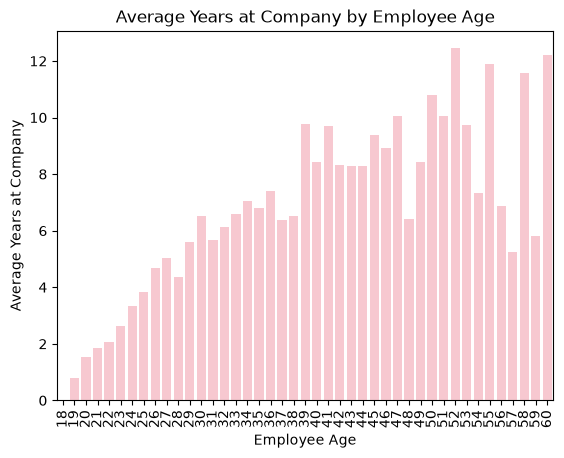

In [42]:
sns.barplot(
    x='Age',
    y='YearsAtCompany',
    data=df,
    estimator='mean',
    color='pink',
    errorbar=None)

plt.title('Average Years at Company by Employee Age')
plt.xlabel('Employee Age')
plt.ylabel('Average Years at Company')
plt.xticks(rotation=90)
plt.show()

**The results show a significant relationship between employees’ age and the number of years they have worked at the company. HR managers can use this information to understand workforce patterns and infer that certain age groups have higher experience than others. This can help them plan employee development, promotions, and retention strategies.**

---

## Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)

#### **Is the average monthly income the same across the five education levels?**

#### H₀: All five education groups have the same average monthly income.
#### H₁: At least one education group's average monthly income is different from the others.

#### Table explaning the Education variable:
|Value|	Education level|
------|----------------|
|1	|Below College|
|2	|College|
|3	|Bachelor|
|4	|Master|
|5	|Doctor|

In [45]:
BC = df[df['Education'] == 1]['MonthlyIncome']
C = df[df['Education'] == 2]['MonthlyIncome']
B = df[df['Education'] == 3]['MonthlyIncome']
M = df[df['Education'] == 4]['MonthlyIncome']
D = df[df['Education'] == 5]['MonthlyIncome']

print(f"mean group1:{np.mean(BC):.2f} ")
print(f"mean group2:{np.mean(C):.2f} ")
print(f"mean group3:{np.mean(B):.2f} ")
print(f"mean group4:{np.mean(M):.2f} ")
print(f"mean group5:{np.mean(D):.2f}\n ")

print(f"group5 (Doctor), has the highest average monthly income:{np.mean(D):.2f}\n ")

f_stat, p_value = stats.f_oneway(BC,C,B,M,D)

print("F-statistic:", f_stat)
print("p-value:", p_value)

if p_value <0.05:
    print(f"\nReject H0: There is evidence that At least one education group's average monthly income is different from the others")
else:
    print(f"\nFailed ot reject H0: There is insufficient evidence to conclude that the group means differ")

mean group1:5640.57 
mean group2:6226.65 
mean group3:6517.26 
mean group4:6832.40 
mean group5:8277.65
 
group5 (Doctor), has the highest average monthly income:8277.65
 
F-statistic: 3.8929774134094077
p-value: 0.003768508926919225

Reject H0: There is evidence that At least one education group's average monthly income is different from the others


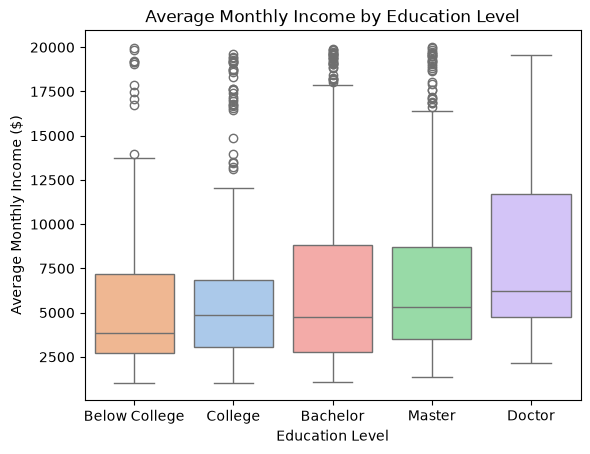

In [47]:
df["Groups"] = df['Education'].map({
    1: "Below College",
    2: "College",
    3: "Bachelor",
    4: "Master",
    5: "Doctor"})

sns.boxplot(
    x='Groups',
    y='MonthlyIncome',
    data=df,
    order=["Below College","College","Bachelor","Master","Doctor"],
    hue='Groups',
    palette="pastel" ,
    legend=False,
   )
plt.title('Average Monthly Income by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Average Monthly Income ($)')
plt.show()

**The results show a significant difference in average monthly income across education levels (p = 0.0038). Employees with a Doctoral degree (Group 5) have the highest average monthly income at 8,277.65, while Group 1 has the lowest at ($)5,640.57. HR managers should review compensation across education levels to understand these differences and make sure pays are fair based on their education levels.**

---

## Part 3: Assessing Decision Errors in HR Policy

### Analysis of Type I and Type II Errors in my ANOVA test

**1. Type I Error (False Positive)**

A Type I error occurs when we reject the null hypothesis even though it is true. In this analysis, it would mean concluding that average monthly income differs across education levels when, in reality, the population mean monthly income is the same for all five education groups. As a result, the company might make unnecessary changes to its salary structure or compensation policies.

**2. Type II Error (False Negative)**

A Type II error occurs when we fail to reject the null hypothesis even though it is false. In this test, it would mean concluding that there is insufficient evidence of a difference in average monthly income across education levels when a real difference actually exists. Consequently, the company might think that its paying policies are unfair.

**3. Which Error Carries a Greater Operational Risk?**

From a corporate governance and employee retention standpoint, I believe a Type II error could be more harmful because the company might miss real salary differences between employees with different education levels. This could make employees feel underpaid and cause them to leave for better-paying jobs. As a result, the company could lose good employees and spend more money hiring and training new ones.